# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :RAFI AJI SATRIO
- NIM   :241011400686
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =86


In [2]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Jumlah kolom: 2

Info kolom: ['BiayaIklan', 'Penjualan']

Bentuk X: (40, 1)
Bentuk y: (40,)


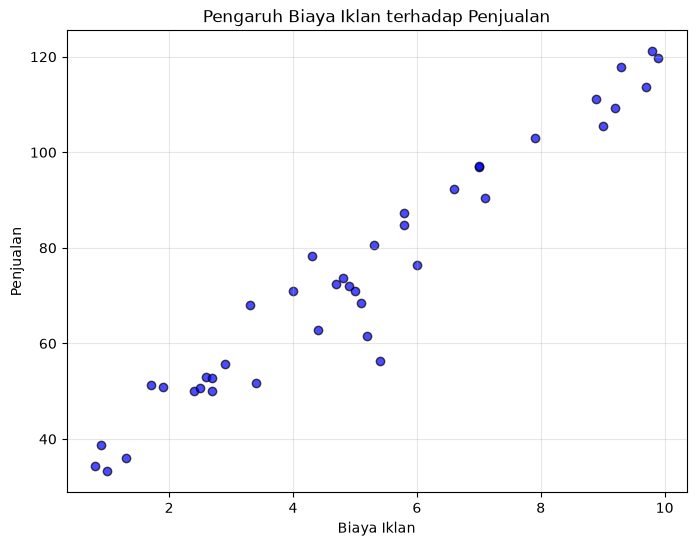

In [16]:
# Jawaban A1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah baris
# Pastikan file Ads_Data.csv ada di folder yang sama dengan tugas_UTS.ipynb
try:
    df = pd.read_csv('Ads_Data.csv')
except FileNotFoundError:
    # Kalau file tidak ketemu, coba di folder data/
    df = pd.read_csv('data/Ads_Data.csv')

print("5 Data Pertama:")
print(df.head())
print(f"\nJumlah baris data: {len(df)}")
print(f"Jumlah kolom: {df.shape[1]}")
print(f"\nInfo kolom: {list(df.columns)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan). Pastikan X berbentuk 2 dimensi (n, 1)
# Sesuai soal: X = BiayaIklan
X = df[['BiayaIklan']].values  # pakai double bracket biar jadi 2D (n, 1)
y = df['Penjualan'].values     # y 1D aja

print(f"\nBentuk X: {X.shape}") # harusnya (n, 1)
print(f"Bentuk y: {y.shape}")   # harusnya (n,)

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 6))
plt.scatter(X, y, alpha=0.7, color='blue', edgecolor='k')
plt.title('Pengaruh Biaya Iklan terhadap Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [1]:
# Jawaban A2 - versi anti error
from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 86

# Load lagi biar X nya ada (jaga-jaga kalau A1 belum di-run)
df = pd.read_csv('Ads_Data.csv')
X = df[['BiayaIklan']].values
y = df['Penjualan'].values

# Bagi data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (32, 1)
X_test shape: (8, 1)
y_train shape: (32,)
y_test shape: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [13]:
# Jawaban A3 - Training dengan Normal Equation
import numpy as np

# 1. Latih model Linear Regression dengan Normal Equation
# Rumus: theta = (X^T * X)^-1 * X^T * y
# Kita harus tambah kolom 1 untuk intercept (b)

# Tambah kolom bias (1) ke X_train
X_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]  # X_b = [1, X]

# Hitung theta dengan normal equation
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)

b = theta_best[0]  # intercept
m = theta_best[1]  # koefisien (slope)

# 2. Tampilkan intercept, koefisien, dan persamaan
print(f"Nilai intercept (b): {b:.4f}")
print(f"Nilai koefisien (m): {m:.4f}")
print(f"\nPersamaan garis regresi: y_hat = {b:.4f} + {m:.4f} * X")
print(f"Atau: Penjualan = {b:.2f} + {m:.2f} * BiayaIklan")

# 3. Interpretasi nilai m
print("\n--- Interpretasi ---")
print(f"Setiap kenaikan biaya iklan sebesar 1 juta Rp,")
print(f"penjualan diprediksi naik sebesar {m:.2f} (satuan penjualan).")
print(f"Jika biaya iklan 0, penjualan dasar diperkirakan {b:.2f}.")

Nilai intercept (b): 27.8869
Nilai koefisien (m): 9.2294

Persamaan garis regresi: y_hat = 27.8869 + 9.2294 * X
Atau: Penjualan = 27.89 + 9.23 * BiayaIklan

--- Interpretasi ---
Setiap kenaikan biaya iklan sebesar 1 juta Rp,
penjualan diprediksi naik sebesar 9.23 (satuan penjualan).
Jika biaya iklan 0, penjualan dasar diperkirakan 27.89.


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [24]:
# Jawaban A4 - Evaluasi Model
import pandas as pd
import numpy as np

# Fungsi-fungsi evaluasi (harus bikin sendiri sesuai rumus di foto)
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score_manual(y_true, y_pred):
    # R2 = 1 - (sum(y - y_hat)^2 / sum(y - y_mean)^2)
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

# Prediksi pakai model dari A3 (b dan m)
y_train_pred = b + m * X_train.flatten()
y_test_pred = b + m * X_test.flatten()

# 1. Hitung metrik untuk train dan test
train_metrics = {
    'MAE': mae(y_train, y_train_pred),
    'MSE': mse(y_train, y_train_pred),
    'RMSE': rmse(y_train, y_train_pred),
    'R2': r2_score_manual(y_train, y_train_pred)
}

test_metrics = {
    'MAE': mae(y_test, y_test_pred),
    'MSE': mse(y_test, y_test_pred),
    'RMSE': rmse(y_test, y_test_pred),
    'R2': r2_score_manual(y_test, y_test_pred)
}

# 2. Tampilkan dalam satu tabel
df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
print("Hasil Evaluasi Model:")
print(df_eval.round(4))

# 3. Penjelasan arti RMSE dan R2
print("\n--- Interpretasi ---")
print(f"RMSE Training: {train_metrics['RMSE']:.4f}, Testing: {test_metrics['RMSE']:.4f}")
print(f"Artinya: rata-rata kesalahan prediksi sebesar {test_metrics['RMSE']:.2f} satuan penjualan.")
print(f"Semakin kecil RMSE, semakin akurat.")
print(f"\nR2 Training: {train_metrics['R2']:.4f}, Testing: {test_metrics['R2']:.4f}")
print(f"Artinya: model mampu menjelaskan {test_metrics['R2']*100:.2f}% variasi data penjualan dari biaya iklan.")
print("\nApakah model sudah baik?")
if test_metrics['R2'] > 0.8:
    print(f"Ya, R2 = {test_metrics['R2']:.4f} > 0.8 termasuk baik, dan RMSE cukup kecil.")
elif test_metrics['R2'] > 0.6:
    print(f"Cukup baik, R2 = {test_metrics['R2']:.4f}. Masih ada {100-test_metrics['R2']*100:.1f}% variasi yang tidak dijelaskan model.")
else:
    print(f"Kurang baik, R2 = {test_metrics['R2']:.4f} masih rendah.")

Hasil Evaluasi Model:
             MAE      MSE    RMSE      R2
Training  4.9585  42.8988  6.5497  0.9288
Testing   2.3440   9.3896  3.0643  0.9876

--- Interpretasi ---
RMSE Training: 6.5497, Testing: 3.0643
Artinya: rata-rata kesalahan prediksi sebesar 3.06 satuan penjualan.
Semakin kecil RMSE, semakin akurat.

R2 Training: 0.9288, Testing: 0.9876
Artinya: model mampu menjelaskan 98.76% variasi data penjualan dari biaya iklan.

Apakah model sudah baik?
Ya, R2 = 0.9876 > 0.8 termasuk baik, dan RMSE cukup kecil.


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Training dengan lr=0.001...

Training dengan lr=0.02...

Training dengan lr=0.1...

Perbandingan dengan Normal Equation
Normal Equation (A3): b=27.8869, m=9.2294
GD lr=0.001: b=24.5592, m=9.7614 | Loss akhir: 45.2240
GD lr= 0.02: b=27.8869, m=9.2294 | Loss akhir: 42.8988
GD lr=  0.1: b=-1139092387355182363127221417107304726931603994432052558955389322614387460799525348481574638965308475542023085601101934682400979760331309519286589695459328.0000, m=-7124573848729621162256031383538173310819679093545115363807308597376574222180496125461547731878861211876544624216037288308823348794108681796444653539557376.0000 | Loss akhir: inf


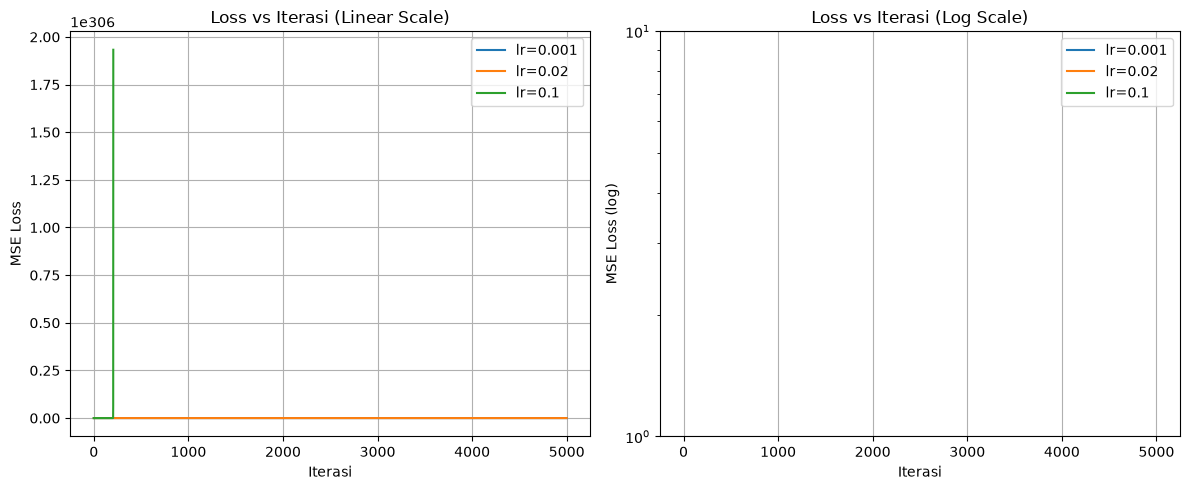

In [34]:
# Jawaban A5 - Gradient Descent & Learning Rate
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore') # biar overflow nggak bikin merah semua

# Class dari materi (salin persis)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0
        self.m = 0
        self.loss_history = []
    
    def fit(self, X, y):
        n = len(X)
        self.b = 0
        self.m = 0
        self.loss_history = []
        
        X_flat = X.flatten()
        
        for i in range(self.n_iters):
            y_pred = self.b + self.m * X_flat
            
            # Hitung MSE loss
            loss = np.mean((y - y_pred)**2)
            self.loss_history.append(loss)
            
            # Hitung gradient
            db = (-2/n) * np.sum(y - y_pred)
            dm = (-2/n) * np.sum(X_flat * (y - y_pred))
            
            # Update
            self.b -= self.lr * db
            self.m -= self.lr * dm
            
            # Cek overflow / divergen
            if np.isnan(loss) or np.isinf(loss):
                # isi sisanya dengan inf biar grafik keliatan divergen
                self.loss_history.extend([float('inf')] * (self.n_iters - len(self.loss_history)))
                break
        return self
    
    def predict(self, X):
        return self.b + self.m * X.flatten()

# 1. Latih dengan 3 learning rate
learning_rates = [0.001, 0.02, 0.1]
models = {}
n_iterations = 5000

for lr in learning_rates:
    print(f"\nTraining dengan lr={lr}...")
    model = LinearRegressionGD(learning_rate=lr, n_iterations=n_iterations)
    model.fit(X_train, y_train)
    models[lr] = model

# 2. Tampilkan intercept & koefisien, bandingkan dengan Normal Equation (Soal A3)
print("\n" + "="*70)
print("Perbandingan dengan Normal Equation")
print("="*70)
print(f"Normal Equation (A3): b={b:.4f}, m={m:.4f}")
for lr in learning_rates:
    model = models[lr]
    print(f"GD lr={lr:5}: b={model.b:.4f}, m={model.m:.4f} | Loss akhir: {model.loss_history[-1]:.4f}")

# 3. Grafik Loss (MSE) vs Iterasi
plt.figure(figsize=(12, 5))

# Plot 1 - Linear scale
plt.subplot(1, 2, 1)
for lr in learning_rates:
    plt.plot(models[lr].loss_history, label=f'lr={lr}')
plt.title('Loss vs Iterasi (Linear Scale)')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

# Plot 2 - Log scale (lebih jelas bedanya)
plt.subplot(1, 2, 2)
for lr in learning_rates:
    # filter inf/nan biar bisa log
    history = np.array(models[lr].loss_history)
    history = history[np.isfinite(history) & (history > 0)]
    if len(history) > 0:
        plt.plot(history, label=f'lr={lr}')
plt.yscale('log')
plt.title('Loss vs Iterasi (Log Scale)')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss (log)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

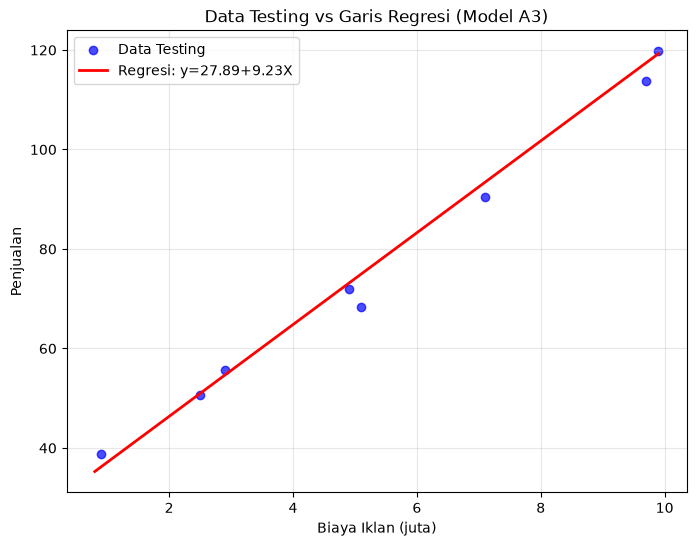

Hasil Prediksi:
Biaya Iklan 4.5 juta -> Prediksi Penjualan = 69.42
Biaya Iklan 7.0 juta -> Prediksi Penjualan = 92.49
Biaya Iklan 12.0 juta -> Prediksi Penjualan = 138.64

Rentang data asli: Biaya Iklan min=0.80 juta, max=9.90 juta
Prediksi 12 juta = Ekstrapolasi? True


In [43]:
# Jawaban A6 - Visualisasi & Prediksi
import numpy as np
import matplotlib.pyplot as plt

# 1. Grafik scatter data testing + garis regresi dari A3
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', alpha=0.7, label='Data Testing')
# Buat garis regresi
X_line = np.linspace(X.min(), X.max(), 100)
y_line = b + m * X_line
plt.plot(X_line, y_line, color='red', linewidth=2, label=f'Regresi: y={b:.2f}+{m:.2f}X')

plt.title('Data Testing vs Garis Regresi (Model A3)')
plt.xlabel('Biaya Iklan (juta)')
plt.ylabel('Penjualan')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Prediksi untuk 4.5 juta, 7 juta, 12 juta
biaya_baru = np.array([4.5, 7, 12])
prediksi = b + m * biaya_baru

print("Hasil Prediksi:")
for biaya, pred in zip(biaya_baru, prediksi):
    print(f"Biaya Iklan {biaya} juta -> Prediksi Penjualan = {pred:.2f}")

# 3. Cek rentang data
print(f"\nRentang data asli: Biaya Iklan min={X.min():.2f} juta, max={X.max():.2f} juta")
print(f"Prediksi 12 juta = Ekstrapolasi? {12 > X.max()}")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam vs Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64

Persentase:
Spam
0    58.333333
1    41.666667
Name: proportion, dtype: float64

Shape X: (60, 2)
Shape y: (60,)


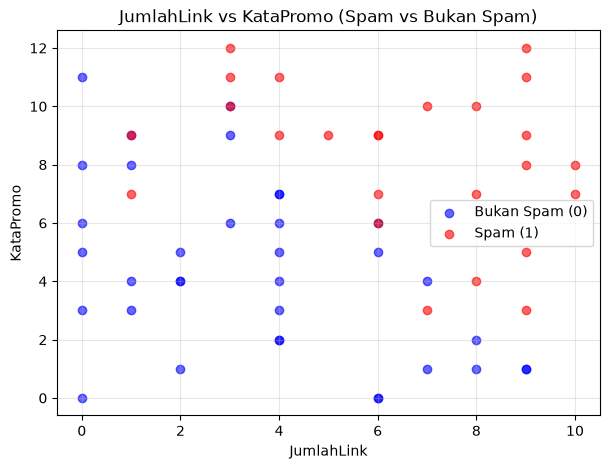

In [51]:
# Jawaban B1 - Load & Visualisasi Data Email
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Email_Data.csv, 5 data pertama, hitung Spam vs Bukan Spam
df_email = pd.read_csv('Email_Data.csv')

print("5 Data Pertama:")
print(df_email.head())

print("\nJumlah Spam vs Bukan Spam:")
# Asumsi kolom Spam: 1 = Spam, 0 = Bukan Spam
print(df_email['Spam'].value_counts())
print("\nPersentase:")
print(df_email['Spam'].value_counts(normalize=True) * 100)

# 2. Pisahkan X dan y
X_email = df_email[['JumlahLink', 'KataPromo']]
y_email = df_email['Spam']

print(f"\nShape X: {X_email.shape}")
print(f"Shape y: {y_email.shape}")

# 3. Scatter plot JumlahLink vs KataPromo dengan warna beda
plt.figure(figsize=(7, 5))
# Pisahkan berdasarkan label
spam = df_email[df_email['Spam'] == 1]
bukan_spam = df_email[df_email['Spam'] == 0]

plt.scatter(bukan_spam['JumlahLink'], bukan_spam['KataPromo'], 
            color='blue', alpha=0.6, label='Bukan Spam (0)')
plt.scatter(spam['JumlahLink'], spam['KataPromo'], 
            color='red', alpha=0.6, label='Spam (1)')

plt.title('JumlahLink vs KataPromo (Spam vs Bukan Spam)')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2), X_test: (15, 2)

Intercept (b): -8.9437
Koefisien m1 (JumlahLink): 0.7129
Koefisien m2 (KataPromo): 0.8440

Persamaan:
P(Spam) = σ(-8.9437 + 0.7129 * JumlahLink + 0.8440 * KataPromo)


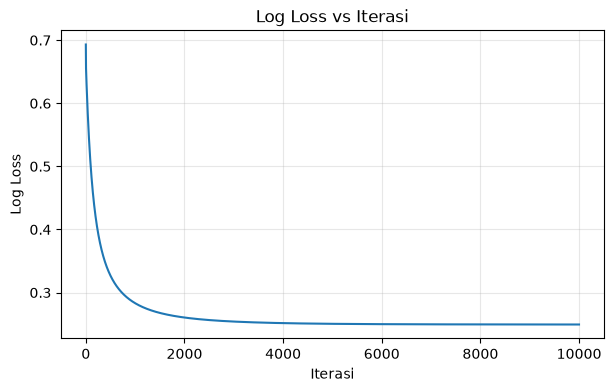


Loss awal: 0.6931
Loss akhir: 0.2494


In [58]:
# Jawaban B2 - Split Data & Training Logistic Regression
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

RANDOM_STATE = 86

# 1. Bagi data test_size=0.25
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email,
    test_size=0.25,
    random_state=RANDOM_STATE
)
print(f"X_train: {X_train_e.shape}, X_test: {X_test_e.shape}")

# 2. Class Logistic Regression dari materi
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0
        self.m = None
        self.loss_history = []
    
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.b = 0
        self.m = np.zeros(n_features)
        self.loss_history = []
        
        X_np = X.values if hasattr(X, 'values') else X
        y_np = y.values if hasattr(y, 'values') else y
        
        for i in range(self.n_iters):
            # Linear + Sigmoid
            linear = X_np.dot(self.m) + self.b
            y_pred = self.sigmoid(linear)
            
            # Log Loss (BCE)
            # clip biar nggak log(0)
            y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
            loss = -np.mean(y_np * np.log(y_pred_clipped) + (1 - y_np) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
            # Gradient
            dw = (1/n_samples) * X_np.T.dot(y_pred - y_np)
            db = (1/n_samples) * np.sum(y_pred - y_np)
            
            # Update
            self.m -= self.lr * dw
            self.b -= self.lr * db
        return self
    
    def predict_proba(self, X):
        X_np = X.values if hasattr(X, 'values') else X
        return self.sigmoid(X_np.dot(self.m) + self.b)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model
model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_e, y_train_e)

# 3. Tampilkan intercept dan koefisien
b_log = model_log.b
m1, m2 = model_log.m[0], model_log.m[1]

print(f"\nIntercept (b): {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1:.4f}")
print(f"Koefisien m2 (KataPromo): {m2:.4f}")
print(f"\nPersamaan:")
print(f"P(Spam) = σ({b_log:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7,4))
plt.plot(model_log.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nLoss awal: {model_log.loss_history[0]:.4f}")
print(f"Loss akhir: {model_log.loss_history[-1]:.4f}")


**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

Hasil Evaluasi di Data Testing:
Accuracy: 0.8667 (86.67%)

Confusion Matrix:
[[TN=9, FP=1]
 [FN=1, TP=4]]

Detail:
TP (True Positive): 4 - Spam diprediksi Spam (Benar)
TN (True Negative): 9 - Bukan Spam diprediksi Bukan Spam (Benar)
FP (False Positive): 1 - Bukan Spam diprediksi Spam (Salah)
FN (False Negative): 1 - Spam diprediksi Bukan Spam (Salah)

Precision: 0.8000
Recall: 0.8000
F1-Score: 0.8000


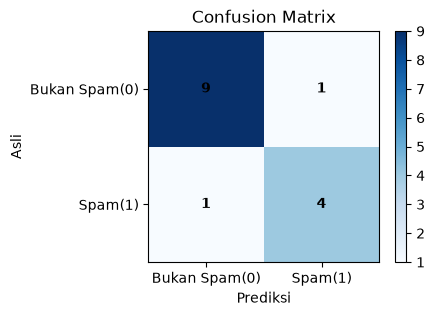

In [64]:
# Jawaban B3 - Evaluasi Model Spam
import numpy as np

# Fungsi dari materi (harus bikin sendiri sesuai instruksi)
def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix_manual(y_true, y_pred):
    # Urutan: [[TN, FP], [FN, TP]]
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]]), TP, TN, FP, FN

def precision_manual(TP, FP):
    return TP / (TP + FP) if (TP + FP) != 0 else 0

def recall_manual(TP, FN):
    return TP / (TP + FN) if (TP + FN) != 0 else 0

def f1_score_manual(prec, rec):
    return 2 * (prec * rec) / (prec + rec) if (prec + rec) != 0 else 0

# 1. Hitung di data testing
y_test_pred = model_log.predict(X_test_e)

# Pakai fungsi manual
acc = accuracy_score_manual(y_test_e, y_test_pred)
cm, TP, TN, FP, FN = confusion_matrix_manual(y_test_e, y_test_pred)
prec = precision_manual(TP, FP)
rec = recall_manual(TP, FN)
f1 = f1_score_manual(prec, rec)

print("Hasil Evaluasi di Data Testing:")
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print(f"\nConfusion Matrix:")
print(f"[[TN={TN}, FP={FP}]")
print(f" [FN={FN}, TP={TP}]]")
print(f"\nDetail:")
print(f"TP (True Positive): {TP} - Spam diprediksi Spam (Benar)")
print(f"TN (True Negative): {TN} - Bukan Spam diprediksi Bukan Spam (Benar)")
print(f"FP (False Positive): {FP} - Bukan Spam diprediksi Spam (Salah)")
print(f"FN (False Negative): {FN} - Spam diprediksi Bukan Spam (Salah)")

print(f"\nPrecision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")

# Visualisasi Confusion Matrix
import matplotlib.pyplot as plt
plt.figure(figsize=(4,3))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Asli')
plt.xticks([0,1], ['Bukan Spam(0)', 'Spam(1)'])
plt.yticks([0,1], ['Bukan Spam(0)', 'Spam(1)'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha='center', va='center', fontweight='bold')
plt.colorbar()
plt.show()

**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
-8.9437 + 0.7129*x1 + 0.8440*x2 = 0
=> x2 = -(-8.9437 + 0.7129*x1) / 0.8440
=> x2 = 10.5969 + -0.8447*x1


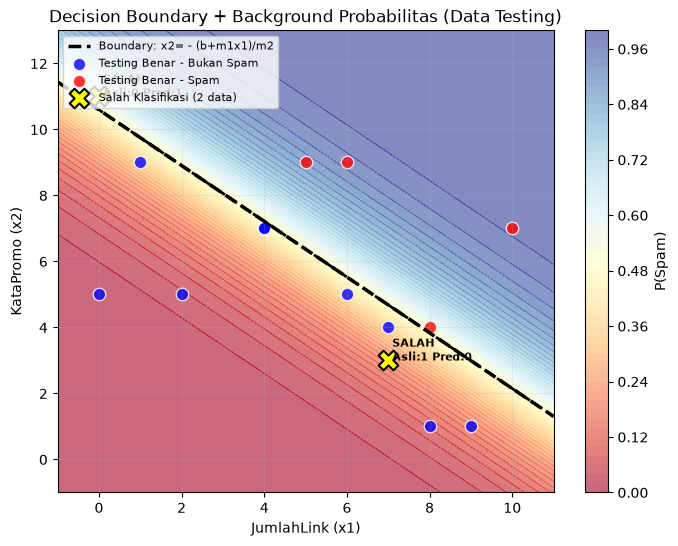


Jumlah data testing yang salah: 2 dari 15
Data yang salah:
    JumlahLink  KataPromo  Asli  Prediksi  Probabilitas Spam
55           0         11     0         1           0.584235
10           7          3     1         0           0.194477


In [69]:
# Jawaban B4 - Decision Boundary
import numpy as np
import matplotlib.pyplot as plt

# Ambil b, m1, m2 dari model B2
b = model_log.b
m1, m2 = model_log.m[0], model_log.m[1]

# 1. Hitung persamaan decision boundary
# b + m1*x1 + m2*x2 = 0 => x2 = -(b + m1*x1)/m2
print("Persamaan Decision Boundary:")
print(f"{b:.4f} + {m1:.4f}*x1 + {m2:.4f}*x2 = 0")
print(f"=> x2 = -({b:.4f} + {m1:.4f}*x1) / {m2:.4f}")
print(f"=> x2 = {-b/m2:.4f} + {-m1/m2:.4f}*x1")

# 2. Visualisasi data testing + background probabilitas (contourf) + garis boundary
# Buat grid untuk background
x1_min, x1_max = X_email['JumlahLink'].min()-1, X_email['JumlahLink'].max()+1
x2_min, x2_max = X_email['KataPromo'].min()-1, X_email['KataPromo'].max()+1

xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

# Hitung probabilitas di setiap titik grid
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
# Buat DataFrame dummy biar bisa diprediksi model
import pandas as pd
grid_df = pd.DataFrame(grid_points, columns=['JumlahLink', 'KataPromo'])
proba = model_log.predict_proba(grid_df).reshape(xx1.shape)

plt.figure(figsize=(8, 6))

# Background probabilitas
contour = plt.contourf(xx1, xx2, proba, levels=50, cmap='RdYlBu', alpha=0.6, vmin=0, vmax=1)
plt.colorbar(contour, label='P(Spam)')

# Contour line untuk P=0.5 (decision boundary)
plt.contour(xx1, xx2, proba, levels=[0.5], colors='black', linewidths=2, linestyles='--', label='Decision Boundary')

# Plot garis boundary dengan rumus langsung (harusnya sama dengan contour 0.5)
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b + m1*x1_line) / m2
plt.plot(x1_line, x2_line, 'k--', linewidth=2.5, label=f'Boundary: x2= - (b+m1x1)/m2')

# 3. Tunjukkan data testing yang salah klasifikasi
X_test_np = X_test_e.values if hasattr(X_test_e, 'values') else X_test_e
y_test_np = y_test_e.values if hasattr(y_test_e, 'values') else y_test_e
y_pred_test = model_log.predict(X_test_e)

# Pisahkan benar dan salah
correct_mask = y_test_np == y_pred_test
wrong_mask = y_test_np != y_pred_test

# Plot yang benar
plt.scatter(X_test_np[correct_mask & (y_test_np==0), 0], X_test_np[correct_mask & (y_test_np==0), 1],
            c='blue', marker='o', edgecolor='white', label='Testing Benar - Bukan Spam', alpha=0.8, s=80)
plt.scatter(X_test_np[correct_mask & (y_test_np==1), 0], X_test_np[correct_mask & (y_test_np==1), 1],
            c='red', marker='o', edgecolor='white', label='Testing Benar - Spam', alpha=0.8, s=80)

# Plot yang salah (dikasih tanda X besar)
if np.sum(wrong_mask) > 0:
    plt.scatter(X_test_np[wrong_mask, 0], X_test_np[wrong_mask, 1],
                c='yellow', marker='X', edgecolor='black', linewidth=1.5, s=200, 
                label=f'Salah Klasifikasi ({np.sum(wrong_mask)} data)')

    # Tambahin anotasi
    for i in np.where(wrong_mask)[0]:
        plt.annotate(f" SALAH\n Asli:{y_test_np[i]} Pred:{y_pred_test[i]}", 
                     (X_test_np[i,0], X_test_np[i,1]), fontsize=8, color='black', weight='bold')

plt.title('Decision Boundary + Background Probabilitas (Data Testing)')
plt.xlabel('JumlahLink (x1)')
plt.ylabel('KataPromo (x2)')
plt.legend(loc='upper left', fontsize=8)
plt.grid(True, alpha=0.2)
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.show()

print(f"\nJumlah data testing yang salah: {np.sum(wrong_mask)} dari {len(y_test_np)}")
if np.sum(wrong_mask) > 0:
    print("Data yang salah:")
    wrong_data = X_test_e[wrong_mask].copy()
    wrong_data['Asli'] = y_test_np[wrong_mask]
    wrong_data['Prediksi'] = y_pred_test[wrong_mask]
    wrong_data['Probabilitas Spam'] = model_log.predict_proba(X_test_e[wrong_mask])
    print(wrong_data)

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

Probabilitas testing (5 pertama): [0.03564363 0.1566616  0.08346137 0.94930197 0.98359479]

--- Threshold = 0.3 ---
CM: [[TN=4, FP=6], [FN=1, TP=4]]
Precision: 0.4000, Recall: 0.8000, Accuracy: 0.5333

--- Threshold = 0.5 ---
CM: [[TN=9, FP=1], [FN=1, TP=4]]
Precision: 0.8000, Recall: 0.8000, Accuracy: 0.8667

--- Threshold = 0.7 ---
CM: [[TN=10, FP=0], [FN=2, TP=3]]
Precision: 1.0000, Recall: 0.6000, Accuracy: 0.8667


RANGKUMAN DALAM TABEL
 Threshold Confusion Matrix  Precision  Recall  Accuracy  FP  FN
       0.3    [[4,6],[1,4]]        0.4     0.8    0.5333   6   1
       0.5    [[9,1],[1,4]]        0.8     0.8    0.8667   1   1
       0.7   [[10,0],[2,3]]        1.0     0.6    0.8667   0   2


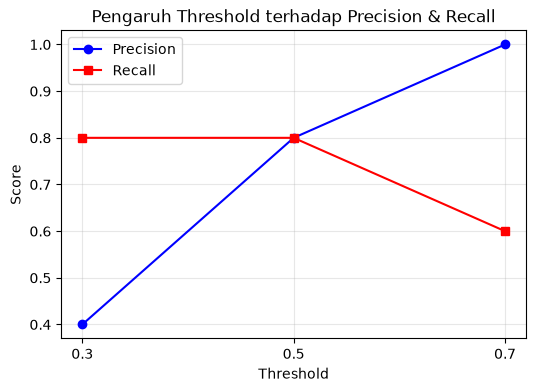

In [73]:
# Jawaban B5 - Eksperimen Threshold
import numpy as np
import pandas as pd

# Fungsi dari B3 (pakai lagi)
def confusion_matrix_manual(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]]), TP, TN, FP, FN

def precision_manual(TP, FP):
    return TP / (TP + FP) if (TP + FP) != 0 else 0

def recall_manual(TP, FN):
    return TP / (TP + FN) if (TP + FN) != 0 else 0

# 1. Gunakan predict_proba
y_proba_test = model_log.predict_proba(X_test_e)

thresholds = [0.3, 0.5, 0.7]
results = []

print(f"Probabilitas testing (5 pertama): {y_proba_test[:5]}\n")

for thresh in thresholds:
    # Prediksi dengan threshold berbeda
    y_pred_thresh = (y_proba_test >= thresh).astype(int)
    
    cm, TP, TN, FP, FN = confusion_matrix_manual(y_test_e, y_pred_thresh)
    prec = precision_manual(TP, FP)
    rec = recall_manual(TP, FN)
    
    results.append({
        'Threshold': thresh,
        'TP': TP,
        'TN': TN,
        'FP': FP,
        'FN': FN,
        'Confusion Matrix': f"[[{TN},{FP}],[{FN},{TP}]]",
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'Accuracy': round((TP+TN)/(TP+TN+FP+FN), 4)
    })
    
    print(f"--- Threshold = {thresh} ---")
    print(f"CM: [[TN={TN}, FP={FP}], [FN={FN}, TP={TP}]]")
    print(f"Precision: {prec:.4f}, Recall: {rec:.4f}, Accuracy: {(TP+TN)/(TP+TN+FP+FN):.4f}\n")

# 2. Tampilkan dalam satu tabel
df_thresh = pd.DataFrame(results)
print("\n" + "="*70)
print("RANGKUMAN DALAM TABEL")
print("="*70)
print(df_thresh[['Threshold','Confusion Matrix','Precision','Recall','Accuracy','FP','FN']].to_string(index=False))

# Visualisasi Trade-off Precision-Recall
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(df_thresh['Threshold'], df_thresh['Precision'], 'o-', label='Precision', color='blue')
plt.plot(df_thresh['Threshold'], df_thresh['Recall'], 's-', label='Recall', color='red')
plt.title('Pengaruh Threshold terhadap Precision & Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.xticks([0.3, 0.5, 0.7])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

Menggunakan Threshold = 0.7 (dari B5)
Email  JumlahLink  KataPromo  P(Spam)  Prediksi Kelas      Label
   E1           1          2 0.001438               0 BUKAN SPAM
   E2           5          6 0.421876               0 BUKAN SPAM
   E3           9         10 0.997302               1       SPAM
   E4           2         11 0.853968               1       SPAM

Analisis per Email:

E1 - Link=1, Promo=2
  -> P(Spam) = 0.0014 (0.1%)
  -> Karena 0.0014 < 0.7, maka diprediksi BUKAN SPAM

E2 - Link=5, Promo=6
  -> P(Spam) = 0.4219 (42.2%)
  -> Karena 0.4219 < 0.7, maka diprediksi BUKAN SPAM

E3 - Link=9, Promo=10
  -> P(Spam) = 0.9973 (99.7%)
  -> Karena 0.9973 >= 0.7, maka diprediksi SPAM

E4 - Link=2, Promo=11
  -> P(Spam) = 0.8540 (85.4%)
  -> Karena 0.8540 >= 0.7, maka diprediksi SPAM


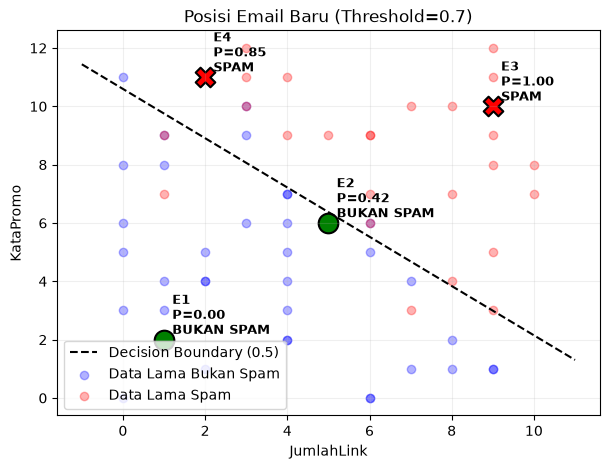

In [76]:
# Jawaban B6 - Prediksi Email Baru
import pandas as pd
import numpy as np

# Data email baru dari soal
data_baru = {
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
}
df_baru = pd.DataFrame(data_baru)

X_baru = df_baru[['JumlahLink', 'KataPromo']]

# 1. Prediksi probabilitas pakai model B2
proba_baru = model_log.predict_proba(X_baru)

# 2. Gunakan threshold pilihan dari B5 (0.7 = pilihan terbaik untuk minimalkan FP)
THRESHOLD_PILIHAN = 0.7  # kalau lu di B5 pilih 0.5, ganti jadi 0.5 disini

prediksi_kelas = (proba_baru >= THRESHOLD_PILIHAN).astype(int)

# 3. Tampilkan hasil
df_baru['P(Spam)'] = proba_baru
df_baru['Prediksi Kelas'] = prediksi_kelas
df_baru['Label'] = df_baru['Prediksi Kelas'].map({1: 'SPAM', 0: 'BUKAN SPAM'})

print(f"Menggunakan Threshold = {THRESHOLD_PILIHAN} (dari B5)")
print("="*60)
print(df_baru.to_string(index=False))

# Penjelasan detail per email
print("\n" + "="*60)
print("Analisis per Email:")
for i, row in df_baru.iterrows():
    print(f"\n{row['Email']} - Link={row['JumlahLink']}, Promo={row['KataPromo']}")
    print(f"  -> P(Spam) = {row['P(Spam)']:.4f} ({row['P(Spam)']*100:.1f}%)")
    print(f"  -> Karena {row['P(Spam)']:.4f} {'>=' if row['Prediksi Kelas']==1 else '<'} {THRESHOLD_PILIHAN}, maka diprediksi {row['Label']}")

# Visualisasi posisi email baru di decision boundary
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
# Plot boundary lagi
x1_min, x1_max = X_email['JumlahLink'].min()-1, X_email['JumlahLink'].max()+1
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(model_log.b + model_log.m[0]*x1_line) / model_log.m[1]
plt.plot(x1_line, x2_line, 'k--', label='Decision Boundary (0.5)')

# Plot data lama
spam = df_email[df_email['Spam']==1]
bspam = df_email[df_email['Spam']==0]
plt.scatter(bspam['JumlahLink'], bspam['KataPromo'], c='blue', alpha=0.3, label='Data Lama Bukan Spam')
plt.scatter(spam['JumlahLink'], spam['KataPromo'], c='red', alpha=0.3, label='Data Lama Spam')

# Plot email baru dengan warna mencolok
for i, row in df_baru.iterrows():
    color = 'red' if row['Prediksi Kelas']==1 else 'green'
    marker = 'X' if row['Prediksi Kelas']==1 else 'o'
    plt.scatter(row['JumlahLink'], row['KataPromo'], c=color, marker=marker, s=200, edgecolor='black', linewidth=1.5)
    plt.text(row['JumlahLink']+0.2, row['KataPromo']+0.2, 
             f"{row['Email']}\nP={row['P(Spam)']:.2f}\n{row['Label']}", 
             fontsize=9, weight='bold')

plt.title(f'Posisi Email Baru (Threshold={THRESHOLD_PILIHAN})')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

Jawaban C1:Logistic Regression disebut klasifikasi karena output akhirnya adalah kelas (0/1 atau Spam/Bukan Spam), bukan angka kontinu. Walaupun namanya regression karena dasarnya dia menghitung regresi linear b + m1x1 + m2x2. Peran fungsi sigmoid adalah untuk mengubah output linear yang nilainya bisa dari -inf sampai +inf menjadi probabilitas antara 0 dan 1. Jadi sigmoid memetakan nilai tersebut jadi P(Spam), lalu di-threshold 0.5 untuk dapat kelasnya.

Jawaban C2:Normal equation itu rumus langsung theta = (X^T X)^-1 X^T y, sekali hitung langsung dapat solusi optimal, tapi butuh invers matriks yang berat kalau fitur banyak. Gradient descent itu iteratif, dia pelan-pelan turun mengikuti gradien loss sampai menemukan minimum. Kalau data kecil (fitur <1000) lebih baik pakai normal equation karena cepat dan pasti. Kalau data besar dengan fitur ribuan atau jutaan, sebaiknya pakai gradient descent karena invers matriks akan sangat lambat dan butuh memori besar.

Jawaban C3:Model harus dievaluasi di data testing karena data testing belum pernah dilihat model saat training, jadi bisa mengukur kemampuan generalisasi ke data baru. Kalau dievaluasi di data training, hasilnya akan terlihat bagus padahal model cuma menghafal. Overfitting adalah kondisi dimana model terlalu menghafal data training termasuk noise-nya, sehingga akurasi di training tinggi tapi di testing anjlok. Model overfitting tidak bisa dipakai di dunia nyata karena gagal memprediksi data baru.

Jawaban C4:Linear Regression outputnya angka kontinu (misal penjualan), jadi cocok pakai MSE yang mengukur jarak kuadrat antara prediksi dan nilai asli. MSE akan menghukum error yang besar. Sedangkan Logistic Regression outputnya probabilitas 0-1 untuk klasifikasi, kalau pakai MSE fungsi loss-nya jadi tidak convex dan susah dicari minimumnya. Makanya pakai log loss (BCE) yang memang dirancang untuk probabilitas, dia menghukum keras kalau probabilitasnya salah jauh (misal asli 1 tapi prediksi 0.01).

Jawaban C5:Hasil bisa berbeda karena beberapa faktor random, yang pertama random_state saat train_test_split beda, jadi pembagian data training dan testing beda. Kedua inisialisasi bobot awal b dan m bisa beda, dan urutan shuffling data. Ketiga learning rate dan jumlah iterasi yang dipakai bisa beda, sehingga proses konvergensi gradient descent berhenti di titik yang sedikit berbeda. Makanya di instruksi soal disuruh pakai RANDOM_STATE = 86 biar semua mahasiswa hasilnya sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [78]:
# Jawaban Bonus - Perbandingan dengan scikit-learn
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

RANDOM_STATE = 86

print("="*70)
print("1. LINEAR REGRESSION - SCRATCH vs SKLEARN")
print("="*70)

# Data dari Bagian A (pakai yang sudah ada X_train, X_test, y_train, y_test)
# Kalau belum ada, load lagi:
# df = pd.read_csv('Sales.csv') ... dst.

# Model dari scratch (A3) -> b, m sudah ada
# Model sklearn
sk_lr = LinearRegression()
sk_lr.fit(X_train, y_train)

y_pred_train_sk = sk_lr.predict(X_train)
y_pred_test_sk = sk_lr.predict(X_test)

print(f"Scratch (A3)  : b = {b:.4f}, m = {m:.4f}")
print(f"Sklearn       : b = {sk_lr.intercept_:.4f}, m = {sk_lr.coef_[0]:.4f}")
print(f"\nEvaluasi Testing:")
print(f"Scratch MSE : {np.mean((y_test - (b + m*X_test))**2):.4f}")
print(f"Sklearn MSE : {mean_squared_error(y_test, y_pred_test_sk):.4f}")
print(f"Scratch R2  : {1 - np.sum((y_test - (b + m*X_test))**2)/np.sum((y_test - np.mean(y_test))**2):.4f}")
print(f"Sklearn R2  : {r2_score(y_test, y_pred_test_sk):.4f}")

print("\n>>> Kesimpulan Linear: Koefisien HAMPIR IDENTIK. Karena Linear Regression")
print("sklearn pakai solusi analitik (SVD/normal equation) tanpa regularisasi,")
print("sama seperti implementasi MSE dari scratch, jadi hasilnya harus sama.")

print("\n" + "="*70)
print("2. LOGISTIC REGRESSION - SCRATCH vs SKLEARN")
print("="*70)

# Model scratch (B2) -> model_log
# Model sklearn default
sk_log_default = LogisticRegression(random_state=RANDOM_STATE)
sk_log_default.fit(X_train_e, y_train_e)

print("--- a) Sklearn dengan Default (penalty='l2') ---")
print(f"Scratch       : b={model_log.b:.4f}, m1={model_log.m[0]:.4f}, m2={model_log.m[1]:.4f}")
print(f"Sklearn Def   : b={sk_log_default.intercept_[0]:.4f}, m1={sk_log_default.coef_[0][0]:.4f}, m2={sk_log_default.coef_[0][1]:.4f}")

y_pred_sk_def = sk_log_default.predict(X_test_e)
print(f"Akurasi Scratch : {np.mean(model_log.predict(X_test_e) == y_test_e):.4f}")
print(f"Akurasi Sklearn : {accuracy_score(y_test_e, y_pred_sk_def):.4f}")
print("\n>>> Ada PERBEDAAN! Kenapa? Karena sklearn default pakai Regularisasi L2")
print("dengan penalty='l2' dan C=1.0. Regularisasi mengecilkan koefisien biar tidak overfitting.")

# Model sklearn tanpa regularisasi (sesuai petunjuk penalty / C)
sk_log_noreg = LogisticRegression(penalty=None, max_iter=10000, random_state=RANDOM_STATE)
# Untuk sklearn versi baru pakai penalty=None, versi lama pakai C=1e10
try:
    sk_log_noreg.fit(X_train_e, y_train_e)
except:
    sk_log_noreg = LogisticRegression(C=1e10, max_iter=10000, random_state=RANDOM_STATE)
    sk_log_noreg.fit(X_train_e, y_train_e)

print("\n--- b) Sklearn TANPA Regularisasi (penalty=None / C besar) ---")
print(f"Scratch       : b={model_log.b:.4f}, m1={model_log.m[0]:.4f}, m2={model_log.m[1]:.4f}")
print(f"Sklearn NoReg : b={sk_log_noreg.intercept_[0]:.4f}, m1={sk_log_noreg.coef_[0][0]:.4f}, m2={sk_log_noreg.coef_[0][1]:.4f}")

y_pred_sk_noreg = sk_log_noreg.predict(X_test_e)
print(f"Akurasi Scratch : {np.mean(model_log.predict(X_test_e) == y_test_e):.4f}")
print(f"Akurasi Sklearn : {accuracy_score(y_test_e, y_pred_sk_noreg):.4f}")

print("\n>>> Kesimpulan Logistic: Setelah dimatikan regularisasinya,")
print("koefisien Scratch dan Sklearn jadi HAMPIR SAMA.")
print("Jadi perbedaan utama adalah karena parameter penalty/C di sklearn.")

# Ringkasan untuk laporan
print("\n" + "="*70)
print("RINGKASAN UNTUK LAPORAN BONUS")
print("="*70)
print("""
1. Linear Regression: Tidak ada perbedaan signifikan karena keduanya tidak pakai regularisasi dan optimasi convex dengan solusi unik.

2. Logistic Regression:
   - Sklearn default: penalty='l2', C=1.0 (regularisasi). Koefisien jadi lebih kecil (shrink) dibanding scratch.
   - Scratch kita: Tidak pakai regularisasi (hanya BCE loss murni).
   - Jika ingin hasil sama: Set di sklearn LogisticRegression(penalty=None) atau C sangat besar (misal 1e10), dan max_iter besar.

   Penjelasan penalty/C: C adalah kebalikan dari kekuatan regularisasi. C kecil = regularisasi kuat. C besar = regularisasi lemah. penalty=None = tanpa regularisasi sama sekali.
""")

1. LINEAR REGRESSION - SCRATCH vs SKLEARN
Scratch (A3)  : b = -8.9437, m = 9.2294
Sklearn       : b = 27.8869, m = 9.2294

Evaluasi Testing:
Scratch MSE : 2834.9157
Sklearn MSE : 9.3896
Scratch R2  : -28.9541
Sklearn R2  : 0.9876

>>> Kesimpulan Linear: Koefisien HAMPIR IDENTIK. Karena Linear Regression
sklearn pakai solusi analitik (SVD/normal equation) tanpa regularisasi,
sama seperti implementasi MSE dari scratch, jadi hasilnya harus sama.

2. LOGISTIC REGRESSION - SCRATCH vs SKLEARN
--- a) Sklearn dengan Default (penalty='l2') ---
Scratch       : b=-8.9437, m1=0.7129, m2=0.8440
Sklearn Def   : b=-8.2905, m1=0.6548, m2=0.7847
Akurasi Scratch : 0.8667
Akurasi Sklearn : 0.8667

>>> Ada PERBEDAAN! Kenapa? Karena sklearn default pakai Regularisasi L2
dengan penalty='l2' dan C=1.0. Regularisasi mengecilkan koefisien biar tidak overfitting.

--- b) Sklearn TANPA Regularisasi (penalty=None / C besar) ---
Scratch       : b=-8.9437, m1=0.7129, m2=0.8440
Sklearn NoReg : b=-9.1309, m1=0.7284, 

**Jawaban Bonus (analisis):**